# Example Solution: Classification Exercise 2026

Below you will find my thought process tackling this task. Note: I do not know the optimal solution for this problem and I'm sure this solution can be improved further -> either from a landing point of view or classification.

Firstly, I decided to tackle the landing success objective and essentially disregard classification as to me this was more interesting. However, I believe that targetting a high Macro F1 score would correlate with a good landing score.

Before writing any code I brainstormed some useful features based on the physics. I decided to build them up in stages as I was not sure how beneficial each one would be. They all work using some projection of the rocket's state into the future (essentially how a MPC controller would do it too). I did not neccessarily make all the changes in order (i fixed the split etc first). I may have taken some of these values from the simulator, but as one of you found out the simulator wasn't hidden in the browser environment.

#### Change 1: Just using velocity and no acceleration.

There are essentially four states we care about: The position at landing, the contact speed, the contact angle and the angular velocity at contact. So therefore I only used these as my observations/states.

The equations for these are:

$$\hat{y} = y + v_yt$$
$$\hat{v}_y = v_y$$
$$\hat{\theta} = \theta + \omega t$$
$$\hat{\omega} = \omega$$

With no acceleration the velocities are just held constant. I evaluate these at $t = 1, 2, 3\,\text{s}$, and stop the projection at first contact with the pad, so the features become the contact state if the rocket lands within the horizon. Contact is detected using the lowest point of the hull/feet, with each point $(x_j, y_j)$ rotated about the centre of mass $c$:

$$g(\hat{y}, \hat{\theta}) = \hat{y} + \min_j \left[ x_j \sin\hat{\theta} + (y_j - c)\cos\hat{\theta} \right]$$

where $g \le 0$ means the rocket has touched down.

I hypothesised that the more important direction was the y direction so only added this at first.

#### Change 2: Adding in acceleration due to gravity

Using basically the same equations as above, we can add the acceleration due to gravity to the height prediction.

Resulting in:

$$\hat{y} = y + v_yt + \frac{1}{2} g t^2$$
$$\hat{v}_y = v_y + g t$$

where $g = -9.80665\,\text{m/s}^2$ (negative because up is positive). The angle equations are unchanged.

Technically, if the rocket angle is not 0 there would also be some torque due to the weight, however I did not consider this here.

#### Change 3: Adding in the drag

The drag term influences both the vertical position projection and the rotation (as a side wind would rotate the rocket, or if the rocket was off-axis).

This leads to these equations:

$$\hat{y} = y + v_yt + \frac{1}{2} a_y t^2$$
$$\hat{v}_y = v_y + a_y t$$
$$\hat{\theta} = \theta + \omega t + \frac{1}{2} \alpha t^2$$
$$\hat{\omega} = \omega + \alpha t$$

where:
$$a_y = \frac{F_y}{m} + g, \qquad \alpha = \frac{\tau}{I}$$

The drag force opposes the velocity *relative to the wind* $\mathbf{w}$:
$$\mathbf{v}_{rel} = \mathbf{v} - \mathbf{w}, \qquad \mathbf{F} = -\frac{1}{2}\rho C_d A\, |\mathbf{v}_{rel}|\, \mathbf{v}_{rel}$$

The drag coefficient depends on the angle of attack $\beta$ (the angle between the rocket axis and $\mathbf{v}_{rel}$), since the rocket has far more drag side-on than end-on:
$$C_d = 0.65 + 15 \sin^2\beta$$

The drag acts at the centre of pressure $c_p$ (37 m up the body), which is above the centre of mass $c$, so it produces a torque:
$$\tau = (c_p - c)\left(-F_y \sin\theta - F_x \cos\theta\right)$$

Since drag depends on the velocity, $a_y$ and $\alpha$ change over time, so instead of using one big $t$ I apply these equations in small steps of $\Delta t = 0.25\,\text{s}$ and recalculate the drag at each step.

#### Change 4: Adding in thrust

The observation also contains the current thrust $T$ and gimbal angle $\delta$. I added these to the projections but they didn't improve the model. The plan was to hold them fixed over the horizon (i.e. assuming the controller keeps doing what it's doing). Therefore, the acceleration terms gain an extra force and torque term as below:

$$F_x \mathrel{+}= -T \sin(\theta + \delta), \qquad F_y \mathrel{+}= T \cos(\theta + \delta)$$
$$\tau \mathrel{+}= (c_e - c)\, T \sin\delta$$

where $c_e$ is the engine position (1 m up the body). Thrust is set to 0 if the rocket is out of fuel. I guess if you think about it, this doesn't really make sense as a basis function as this means the reference point changes depending on the previous action and therefore doesn't really make for stable basis functions.

#### Change 5: Adding the horizontal direction - this I did after the exercise class (you can find the result on the leaderboard in position 5)

Going back to Change 3 (without thrust), I also project the horizontal position and velocity with the same step-wise update:

$$\hat{x} = x + v_xt + \frac{1}{2} a_x t^2$$
$$\hat{v}_x = v_x + a_x t$$

where $a_x = F_x / m$ comes only from drag (no gravity in $x$). The pad centre is at $x = 0$, so $\hat{x}$ is directly how far off the pad the rocket would land.

#### Fix 1: Normalisation

The first fix is in the scaffold, which I think everyone saw and changed. The normalisation was originally applied regardless of whether the model was in training or prediction. This is wrong for two reasons:
1. It would fit the normalisation on the validation set, but use the weights trained with the training normalisation. Therefore it would introduce a shift that would likely make the model perform a lot worse.
2. In predict action it is only fed one observation, so when you try to compute the standard deviation you get 0. Therefore you introduce a divide by 0 error.

#### Fix 2: Splits

This one everyone applied too. The original split was random but with this data the previous state is directly related to the next one. Therefore if this previous state appears in your test data but you have the next state in your training data you essentially have already learned about this position. This is temporal leakage. In order to fix it you can split each run by time or you can just split by run. I favour the latter so you can learn about what actions the model takes near the platform.

#### Fix 3: Class-weighting or class sampling

I applied class weighting as I saw that there was a severe imbalance in the data. A model could get a decent accuracy and therefore loss by just predicting class 2. So instead of assigning loss evenly for each class, I used the following:

$$w_c = \frac{N}{K\,n_c}$$

where $N$ is the number of training rows, $K$ the number of classes and $n_c$ the number of training rows in class $c$. So rare classes get a large weight and common classes a small one, and a class with exactly $N/K$ rows gets a weight of 1. The weights are fitted on the training partition only.

Each row's cross-entropy is then multiplied by the weight of its true class:

$$\mathcal{L} = \frac{\sum_i w_{y_i} \left(-\sum_c y_{ic} \log p_{ic}\right)}{\sum_i w_{y_i}}$$

Every class therefore contributes equally to the total loss, no matter how many rows it has. I left the validation loss unweighted so that it stays comparable between models.

#### Fix 4: L-BFGS with L2 instead of gradient descent

The scaffold trains with plain gradient descent, which needs a learning rate and thousands of epochs, and with early stopping the result depends on when it happens to stop. Since the loss is convex (softmax regression), I swapped it for L-BFGS: a quasi-Newton method that builds an approximation of the curvature from the last few gradient steps and picks its own step size with a line search, so it reaches the minimum in tens to hundreds of iterations. Instead of early stopping, I regularise with an L2 penalty on the weights (not the bias) and tune its strength $\lambda$:

$$\mathcal{L}_{\text{L-BFGS}} = \frac{\sum_i w_{y_i} \left(-\sum_c y_{ic} \log p_{ic}\right)}{\sum_i w_{y_i}} + \frac{\lambda}{2} \lVert W \rVert^2$$

I added this before adding the basis functions because I noticed the tuning was taking upwards of 10 minutes.



In [8]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

# Instead of defining everything in the notebook, I just put the code in a separate file to keep this notebook readable.
from experiment import (SEED, LEARNING_RATES, GD_SETTINGS, L2_PENALTIES, LBFGS_SETTINGS,
                        flight_split, grid_search, load_data, load_stage, metrics)

landings_path = "../landings.csv"
validation_runs_path = "../validation_runs.csv"


In [10]:
def accuracy(y_true, y_pred):
    return (y_true == y_pred).mean()

def macro_f1_score(y_true, y_pred):
    try:
        from sklearn.metrics import f1_score
    except ImportError:
        raise ImportError("scikit-learn is required for this function. Please install it using 'pip install scikit-learn'.")
    return f1_score(y_true, y_pred, average='macro')

def confusion_matrix(y_true, y_pred):
    try:
        from sklearn.metrics import confusion_matrix
    except ImportError:
        raise ImportError("scikit-learn is required for this function. Please install it using 'pip install scikit-learn'.")
    return confusion_matrix(y_true, y_pred)

### Fix 1: Splitting

In [11]:
landings = pd.read_csv(landings_path, float_precision="round_trip")

numerical_features = ["x", "y",  "vx", "vy", "theta", "omega", "fuel_mass", "actual_thrust", "actual_gimbal", "wind_x", "wind_y", "air_density"]
target = "action"

# Split by run, not by row: 
# flight_split shuffles the run IDs with a fixed seed then indexes the landings.
# I do this instead of dropping rows because its faster 
train_mask, val_mask, test_mask = flight_split(landings["run_id"].to_numpy(), seed=SEED)
for name, mask in [("Train", train_mask), ("Val", val_mask), ("Test", test_mask)]:
    print(f"{name} runs: {landings.loc[mask, 'run_id'].nunique()}, rows: {mask.sum()}")

# The controllers expect NumPy arrays.
X, y = landings[numerical_features].to_numpy(), landings[target].to_numpy()
X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]


Train runs: 800, rows: 103680
Val runs: 100, rows: 13095
Test runs: 100, rows: 13233


### Setting a Baseline + Fix 2
In order to have a baseline to compare other models to, I ran the scaffold code (after the normalisation fix). However, to get a reasonable baseline the learning rate must also be tuned. I use a grid search in log space for this, and just run the code with early stopping.

Early stopping is where you monitor the validation loss and when it has not improved in x number of epochs you stop the training and revert to the best validation model seen. This prevents overfitting, whilst making sure you train for enough epochs

In [12]:
# I have 9 different controller files so this is just a way to load them nicely.
controllers = {stage: load_stage(stage) for stage in range(1, 9)}


def run_stage(stage, title):
    """Grid-search one stage, save the best model's weights and show the results."""
    Controller = controllers[stage]
    search = grid_search(Controller, X_train, y_train, X_val, y_val)
    best, name = search["best"], search["parameter"]

    file_name = f"{Controller.__module__}_best.npz"
    search["best_model"].save(file_name)
    print(f"Saved best model ({name}={best[name]:.3g}, val macro F1={best['val_macro_f1']:.3f}) to {file_name}")

    # Summary table, best first
    results = pd.DataFrame(search["rows"])
    display(
        results.sort_values("val_macro_f1", ascending=False)
               .style.format({name: "{:.3g}", "train_loss": "{:.4f}", "val_loss": "{:.4f}",
                              "val_accuracy": "{:.3f}", "val_macro_f1": "{:.3f}"})
               .format("{:.3f}", subset=[c for c in results if c.startswith("f1_class_")])
               .background_gradient(subset=["val_macro_f1"], cmap="Greens")
    )

    # Learning curves: solid = validation, dashed = training, dotted = epoch of the returned weights
    fig, ax = plt.subplots(figsize=(9, 5))
    for value, h in search["histories"].items():
        line, = ax.plot(h["validation_loss"], label=f"{name}={value:.3g}")
        ax.plot(h["train_loss"], ls="--", color=line.get_color(), alpha=.5)
        ax.axvline(h["best_epoch"], color=line.get_color(), ls=":", alpha=.5)
    ax.set(xlabel="Epoch" if Controller.optimizer == "gd" else "L-BFGS iteration",
           ylabel="Cross-entropy", title=f"{title}: learning curves")
    ax.legend(fontsize=8)
    plt.show()
    return search


print(f"Loaded {len(controllers)} stages: {[c.__module__ for c in controllers.values()]}")


Loaded 8 stages: ['01_flight_split', '02_class_weighted', '03_lbfgs', '04_constant_velocity', '05_gravity', '06_drag', '07_thrust', '08_horizontal']


Learning rates: ['3', '1.59', '0.845', '0.448', '0.238', '0.126', '0.0669', '0.0355', '0.0188', '0.01'] {'epochs': 10000, 'patience': 20, 'min_delta': 0.001}
learning_rate=3: val macro F1 0.200, 211 epochs (early_stopping)                                   
learning_rate=1.59: val macro F1 0.200, 294 epochs (early_stopping)                                
learning_rate=0.845: val macro F1 0.198, 409 epochs (early_stopping)                               
learning_rate=0.448: val macro F1 0.194, 538 epochs (early_stopping)                               
learning_rate=0.238: val macro F1 0.183, 690 epochs (early_stopping)                               
learning_rate=0.126: val macro F1 0.176, 840 epochs (early_stopping)                               
learning_rate=0.0669: val macro F1 0.173, 977 epochs (early_stopping)                              
learning_rate=0.0355: val macro F1 0.168, 1136 epochs (early_stopping)                             
learning_rate=0.0188: val macro F1 0.168, 

,learning_rate,best_epoch,epochs_run,stop_reason,train_loss,val_loss,val_accuracy,val_macro_f1,f1_class_0,f1_class_1,f1_class_2,f1_class_3,f1_class_4,f1_class_5,f1_class_6,f1_class_7,f1_class_8,f1_class_9
0,3,191,211,early_stopping,0.7755,0.7800,0.768,0.200,0.838,0.159,0.861,0.134,0.010,0.001,0.000,0.000,0.000,0.000
1,1.59,274,294,early_stopping,0.7786,0.7834,0.768,0.200,0.837,0.150,0.861,0.138,0.010,0.001,0.000,0.000,0.000,0.000
2,0.845,389,409,early_stopping,0.7831,0.7881,0.768,0.198,0.837,0.136,0.861,0.133,0.010,0.001,0.000,0.000,0.000,0.000
3,0.448,518,538,early_stopping,0.7909,0.7960,0.767,0.194,0.832,0.133,0.860,0.108,0.010,0.001,0.000,0.000,0.000,0.000
4,0.238,670,690,early_stopping,0.8020,0.8073,0.765,0.183,0.824,0.085,0.858,0.060,0.000,0.001,0.000,0.000,0.000,0.000
5,0.126,820,840,early_stopping,0.8183,0.8237,0.765,0.176,0.822,0.047,0.858,0.037,0.000,0.000,0.000,0.000,0.000,0.000
6,0.0669,957,977,early_stopping,0.8399,0.8453,0.765,0.173,0.819,0.025,0.858,0.025,0.000,0.000,0.000,0.000,0.000,0.000
7,0.0355,1116,1136,early_stopping,0.8646,0.8700,0.765,0.168,0.818,0.000,0.858,0.006,0.000,0.000,0.000,0.000,0.000,0.000
8,0.0188,1341,1361,early_stopping,0.8917,0.8974,0.764,0.168,0.818,0.000,0.858,0.000,0.000,0.000,0.000,0.000,0.000,0.000
9,0.01,1629,1649,early_stopping,0.9235,0.9297,0.764,0.168,0.818,0.000,0.858,0.000,0.000,0.000,0.000,0.000,0.000,0.000


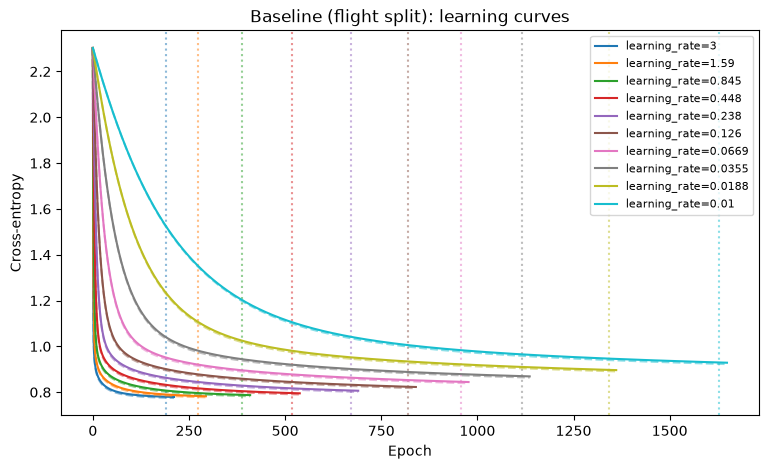

In [13]:
# Gradient descent: learning rates from 3 down to 0.01 (log spaced), early stopping on the validation loss.
# epochs: the maximum, set high (10_000) so early stopping decides when to stop
# patience: how many epochs it waits for the validation loss to improve before stopping
# min_delta: the minimum decrease in validation loss that counts as an improvement
print("Learning rates:", [f"{lr:.3g}" for lr in LEARNING_RATES], GD_SETTINGS)
search_1 = run_stage(1, "Baseline (flight split)")

#### Interpretation

Above shows that the minimum loss and highest validation macro F1 is reached with a learning rate of 3. I will use that value from now on as a comparison.

| Model | learning_rate | train_loss | val_loss | val_F1 | val_accuracy | landing_score | landing_success | tuning_time |
| ----- | ------------- | ---------- | -------- | ------ | ------------ | ------------- | --------------- | ----------- |
| Baseline | 3 | 0.7755 | 0.7800 | 0.200 | 0.768 | 47.1 | 0 | 10min 35s | 

### Class weighting

As I was pretty sure one of the largest differences would be in adding class weightings to the cross entropy loss I decided to do this first before adding basis functions. It also meant I didn't have to re-test and re-tune each one with class weights.

learning_rate=3: val macro F1 0.248, 272 epochs (early_stopping)                                   
learning_rate=1.59: val macro F1 0.247, 399 epochs (early_stopping)                                
learning_rate=0.845: val macro F1 0.246, 576 epochs (early_stopping)                               
learning_rate=0.448: val macro F1 0.246, 826 epochs (early_stopping)                               
learning_rate=0.238: val macro F1 0.244, 1143 epochs (early_stopping)                              
learning_rate=0.126: val macro F1 0.241, 1527 epochs (early_stopping)                              
learning_rate=0.0669: val macro F1 0.238, 1964 epochs (early_stopping)                             
learning_rate=0.0355: val macro F1 0.235, 2464 epochs (early_stopping)                             
learning_rate=0.0188: val macro F1 0.227, 3037 epochs (early_stopping)                             
learning_rate=0.01: val macro F1 0.212, 3567 epochs (early_stopping)                               


,learning_rate,best_epoch,epochs_run,stop_reason,train_loss,val_loss,val_accuracy,val_macro_f1,f1_class_0,f1_class_1,f1_class_2,f1_class_3,f1_class_4,f1_class_5,f1_class_6,f1_class_7,f1_class_8,f1_class_9
0,3,252,272,early_stopping,1.5938,1.5899,0.391,0.248,0.816,0.155,0.458,0.196,0.133,0.268,0.149,0.088,0.146,0.071
1,1.59,379,399,early_stopping,1.5960,1.5932,0.390,0.247,0.815,0.156,0.457,0.195,0.133,0.267,0.149,0.085,0.145,0.070
2,0.845,556,576,early_stopping,1.5996,1.5988,0.388,0.246,0.814,0.157,0.454,0.195,0.140,0.266,0.146,0.083,0.143,0.067
3,0.448,806,826,early_stopping,1.6050,1.6075,0.387,0.246,0.814,0.155,0.454,0.196,0.143,0.264,0.147,0.079,0.142,0.065
4,0.238,1123,1143,early_stopping,1.6136,1.6218,0.384,0.244,0.817,0.156,0.450,0.197,0.143,0.261,0.143,0.076,0.137,0.063
5,0.126,1507,1527,early_stopping,1.6267,1.6441,0.377,0.241,0.821,0.156,0.440,0.196,0.138,0.260,0.145,0.066,0.129,0.057
6,0.0669,1944,1964,early_stopping,1.6456,1.6771,0.370,0.238,0.824,0.159,0.429,0.197,0.129,0.256,0.134,0.063,0.135,0.055
7,0.0355,2444,2464,early_stopping,1.6703,1.7216,0.359,0.235,0.828,0.164,0.413,0.195,0.126,0.251,0.126,0.057,0.135,0.051
8,0.0188,3017,3037,early_stopping,1.7002,1.7794,0.338,0.227,0.832,0.158,0.380,0.188,0.122,0.244,0.120,0.045,0.134,0.042
9,0.01,3547,3567,early_stopping,1.7373,1.8578,0.300,0.212,0.833,0.145,0.312,0.174,0.108,0.233,0.120,0.039,0.120,0.032


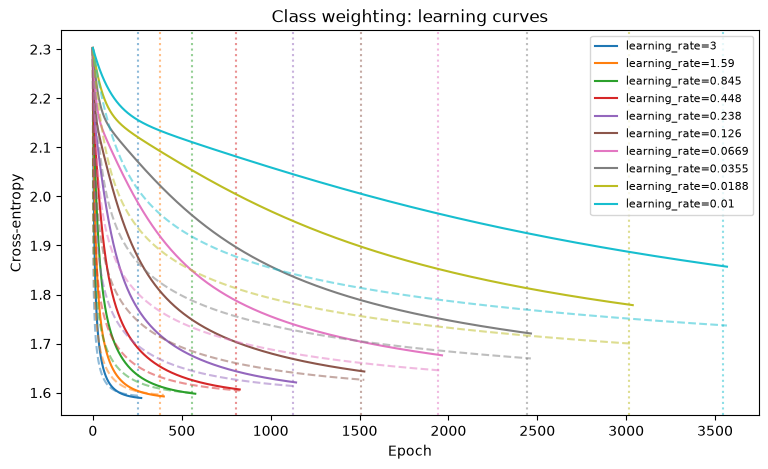

In [14]:
search_2 = run_stage(2, "Class weighting")

#### Interpretation

Class weighting improves the model 

| Model | learning_rate | train_loss | val_loss | val_F1 | val_accuracy | landing_score | landing_success | tuning_time |
| ----- | ------------- | ---------- | -------- | ------ | ------------ | ------------- | --------------- | ----------- |
| Baseline | 3 | 0.7755 | 0.7800 | 0.200 | 0.768 | 47.1 | 0 | 10min 35s | 
| Class Weighting | 3 | 1.5938 | 1.5899 | 0.248 | 0.391 | 60.6 | 0 | 17min 8s |

### L-BFGS with L2

From here on the models are trained with L-BFGS (see Fix 4 above) and, instead of the learning rate, I tune the L2 penalty $\lambda$. Each fit runs until L-BFGS converges (or 1,000 iterations), so there is no early stopping; the penalty is the regulariser. The features are the same as the class-weighted model, so any difference here is purely from the optimiser and regularisation.

L2 penalties: (0.0, 0.0001, 0.001, 0.01, 0.1) {'epochs': 1000, 'patience': None}
l2=0: val macro F1 0.251, 1000 epochs (max_epochs)                                                 
l2=0.0001: val macro F1 0.248, 187 epochs (converged)                                              
l2=0.001: val macro F1 0.246, 108 epochs (converged)                                               
l2=0.01: val macro F1 0.234, 45 epochs (converged)                                                 
l2=0.1: val macro F1 0.193, 26 epochs (converged)                                                  
Saved best model (l2=0, val macro F1=0.251) to 03_lbfgs_best.npz


,l2,best_epoch,epochs_run,stop_reason,train_loss,val_loss,val_accuracy,val_macro_f1,f1_class_0,f1_class_1,f1_class_2,f1_class_3,f1_class_4,f1_class_5,f1_class_6,f1_class_7,f1_class_8,f1_class_9
0,0,1000,1000,max_epochs,1.5661,1.5862,0.389,0.251,0.830,0.152,0.443,0.186,0.159,0.265,0.147,0.096,0.155,0.074
1,0.0001,187,187,converged,1.5909,1.5865,0.392,0.248,0.813,0.154,0.459,0.191,0.134,0.271,0.150,0.092,0.146,0.072
2,0.001,108,108,converged,1.6019,1.6049,0.387,0.246,0.817,0.154,0.453,0.196,0.139,0.265,0.145,0.081,0.146,0.067
3,0.01,45,45,converged,1.6864,1.7305,0.359,0.234,0.835,0.157,0.410,0.193,0.126,0.256,0.122,0.058,0.139,0.048
4,0.1,26,26,converged,1.8768,1.9647,0.261,0.193,0.836,0.125,0.241,0.156,0.073,0.214,0.097,0.043,0.107,0.037


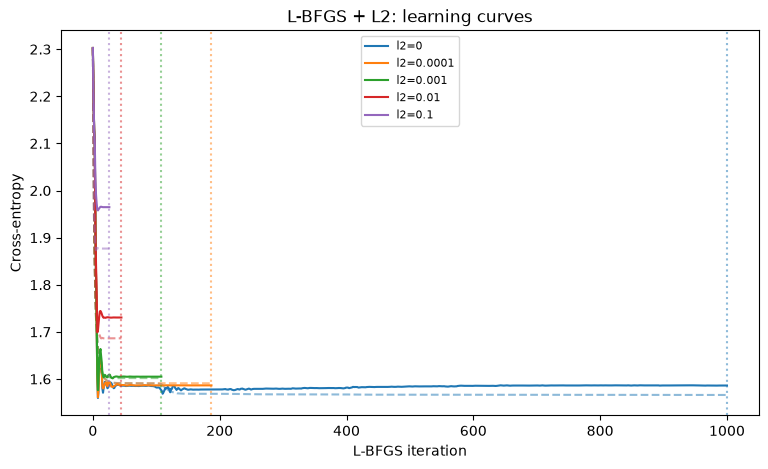

In [15]:
print("L2 penalties:", L2_PENALTIES, LBFGS_SETTINGS)
search_3 = run_stage(3, "L-BFGS + L2")

#### Interpretation

This optimiser is definitely better than just normal gradient descent.

| Model | learning_rate | train_loss | val_loss | val_F1 | val_accuracy | landing_score | landing_success | tuning_time |
| ----- | ------------- | ---------- | -------- | ------ | ------------ | ------------- | --------------- | ----------- |
| Baseline | 3 | 0.7755 | 0.7800 | 0.200 | 0.768 | 47.1 | 0 | 10min 35s | 
| Class Weighting | 3 | 1.5938 | 1.5899 | 0.248 | 0.391 | 60.6 | 0 | 17min 8s |
| L-BFGS | --- | 1.5661 | 1.5862 | 0.251 | 0.389 | 72.9 | 7 | 52s 

As you can see in the table above the optimiser didn't converge within the 1000 epochs. By limiting the number of epochs we are adding in some form of regularisation. It would be possible to get a better score with more epochs but to not spend too much time training I will leave it for now. The performance is already much better.

#### Basis Functions 1 - Constant velocity

The following model uses 12 extra features (12 basis functions) than the original 12 features. For 24 in total. The features are:

y position, vertical velocity, angle and angular velocity
- 1 second in the future
- 2 seconds
- 3 seconds

l2=0: val macro F1 0.282, 1000 epochs (max_epochs)                                                 
l2=0.0001: val macro F1 0.253, 1000 epochs (max_epochs)                                            
l2=0.001: val macro F1 0.248, 170 epochs (converged)                                               
l2=0.01: val macro F1 0.247, 76 epochs (converged)                                                 
l2=0.1: val macro F1 0.216, 47 epochs (converged)                                                  
Saved best model (l2=0, val macro F1=0.282) to 04_constant_velocity_best.npz


,l2,best_epoch,epochs_run,stop_reason,train_loss,val_loss,val_accuracy,val_macro_f1,f1_class_0,f1_class_1,f1_class_2,f1_class_3,f1_class_4,f1_class_5,f1_class_6,f1_class_7,f1_class_8,f1_class_9
0,0,1000,1000,max_epochs,1.4322,1.4719,0.417,0.282,0.824,0.171,0.479,0.205,0.132,0.292,0.123,0.194,0.182,0.218
1,0.0001,1000,1000,max_epochs,1.5528,1.5632,0.395,0.253,0.811,0.178,0.459,0.200,0.132,0.274,0.138,0.100,0.152,0.088
2,0.001,170,170,converged,1.5830,1.5873,0.391,0.248,0.810,0.163,0.459,0.190,0.128,0.271,0.144,0.095,0.151,0.073
3,0.01,76,76,converged,1.6280,1.6434,0.385,0.247,0.825,0.164,0.452,0.197,0.131,0.260,0.141,0.078,0.156,0.063
4,0.1,47,47,converged,1.7819,1.8397,0.335,0.216,0.825,0.137,0.392,0.167,0.082,0.233,0.086,0.055,0.130,0.048


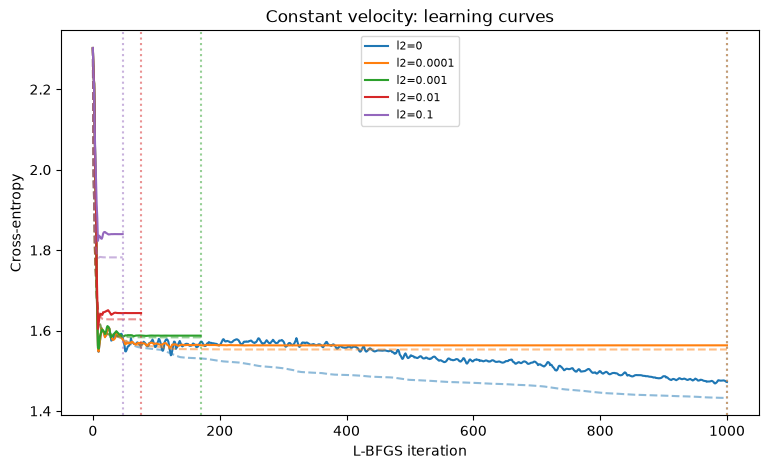

In [16]:
search_4 = run_stage(4, "Constant velocity")

#### Interpretation


| Model | learning_rate | train_loss | val_loss | val_F1 | val_accuracy | landing_score | landing_success | tuning_time |
| ----- | ------------- | ---------- | -------- | ------ | ------------ | ------------- | --------------- | ----------- |
| Baseline | 3 | 0.7755 | 0.7800 | 0.200 | 0.768 | 47.1 | 0 | 10min 35s | 
| Class Weighting | 3 | 1.5938 | 1.5899 | 0.248 | 0.391 | 60.6 | 0 | 17min 8s |
| L-BFGS | --- | 1.5661 | 1.5862 | 0.251 | 0.389 | 72.9 | 7 | 52s |
| Constant Velocity | --- | 1.4322 | 1.4719 | 0.282 | 0.417 | 74.3 | 9 | 2min 19s |

This is again a better lander than the previous one, so the extra basis functions add useful information into the model. Both the accuracy and F1 score also improved. Again it does not converge within the allowed epochs, but the improvements seem like they are helping so we should keep them.

#### Basis Functions 2 - Gravity

Same 24 features, but the projected height and vertical velocity now include gravity (Change 2).

l2=0: val macro F1 0.316, 1000 epochs (max_epochs)                                                 
l2=0.0001: val macro F1 0.276, 517 epochs (converged)                                              
l2=0.001: val macro F1 0.257, 199 epochs (converged)                                               
l2=0.01: val macro F1 0.252, 92 epochs (converged)                                                 
l2=0.1: val macro F1 0.226, 50 epochs (converged)                                                  
Saved best model (l2=0, val macro F1=0.316) to 05_gravity_best.npz


,l2,best_epoch,epochs_run,stop_reason,train_loss,val_loss,val_accuracy,val_macro_f1,f1_class_0,f1_class_1,f1_class_2,f1_class_3,f1_class_4,f1_class_5,f1_class_6,f1_class_7,f1_class_8,f1_class_9
0,0,1000,1000,max_epochs,1.3687,1.3915,0.486,0.316,0.851,0.187,0.580,0.202,0.148,0.319,0.161,0.216,0.278,0.220
1,0.0001,517,517,converged,1.4739,1.4769,0.440,0.276,0.830,0.168,0.525,0.200,0.139,0.286,0.144,0.150,0.183,0.136
2,0.001,199,199,converged,1.5533,1.5465,0.408,0.257,0.813,0.163,0.484,0.196,0.134,0.274,0.146,0.112,0.160,0.090
3,0.01,92,92,converged,1.6125,1.6168,0.399,0.252,0.823,0.164,0.474,0.194,0.132,0.267,0.139,0.080,0.170,0.074
4,0.1,50,50,converged,1.7652,1.8053,0.367,0.226,0.825,0.133,0.444,0.174,0.086,0.238,0.101,0.061,0.133,0.060


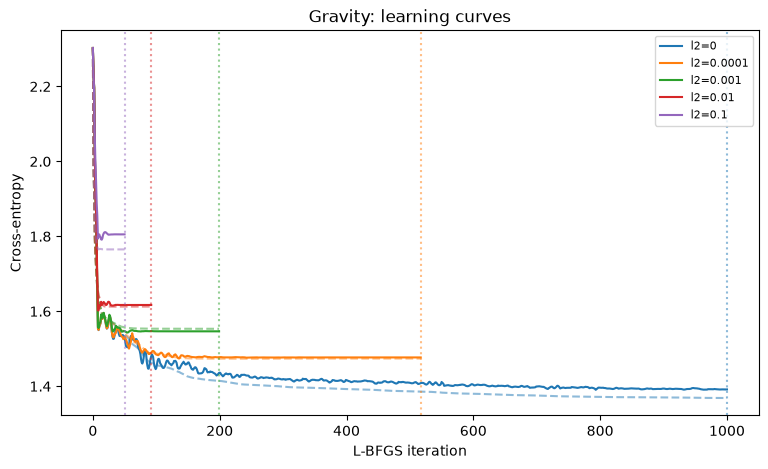

In [17]:
search_5 = run_stage(5, "Gravity")

#### Interpretation


| Model | learning_rate | train_loss | val_loss | val_F1 | val_accuracy | landing_score | landing_success | tuning_time |
| ----- | ------------- | ---------- | -------- | ------ | ------------ | ------------- | --------------- | ----------- |
| Baseline | 3 | 0.7755 | 0.7800 | 0.200 | 0.768 | 47.1 | 0 | 10min 35s | 
| Class Weighting | 3 | 1.5938 | 1.5899 | 0.248 | 0.391 | 60.6 | 0 | 17min 8s |
| L-BFGS | --- | 1.5661 | 1.5862 | 0.251 | 0.389 | 72.9 | 7 | 52s |
| Constant Velocity | --- | 1.4322 | 1.4719 | 0.282 | 0.417 | 74.3 | 9 | 2min 19s |
| Gravity | --- | 1.3687 | 1.3915 | 0.316 | 0.486 | 77.2 | 9 | 1min 40s |

This is again a better lander than the previous one, which makes sense, as adding gravity makes the projection more realistic. Both the accuracy and F1 score also improved again. The reason it is faster is because the other regularisations converged, unlike the previous test. Still there is maybe some performance left on the table as we can run it for more epochs.

#### Basis Functions 3 - Drag

The projection now also includes drag, wind and the drag torque, recalculated every 0.25 s but only added as basis functions at 1s, 2s and 3s (Change 3).

l2=0: val macro F1 0.309, 1000 epochs (max_epochs)                                                 
l2=0.0001: val macro F1 0.278, 866 epochs (converged)                                              
l2=0.001: val macro F1 0.257, 207 epochs (converged)                                               
l2=0.01: val macro F1 0.254, 91 epochs (converged)                                                 
l2=0.1: val macro F1 0.228, 53 epochs (converged)                                                  
Saved best model (l2=0, val macro F1=0.309) to 06_drag_best.npz


,l2,best_epoch,epochs_run,stop_reason,train_loss,val_loss,val_accuracy,val_macro_f1,f1_class_0,f1_class_1,f1_class_2,f1_class_3,f1_class_4,f1_class_5,f1_class_6,f1_class_7,f1_class_8,f1_class_9
0,0,1000,1000,max_epochs,1.3583,1.3833,0.475,0.309,0.850,0.186,0.564,0.204,0.152,0.310,0.149,0.213,0.264,0.201
1,0.0001,866,866,converged,1.4610,1.4657,0.442,0.278,0.832,0.172,0.526,0.203,0.149,0.288,0.146,0.144,0.185,0.137
2,0.001,207,207,converged,1.5388,1.5379,0.410,0.257,0.810,0.156,0.488,0.192,0.137,0.276,0.149,0.112,0.160,0.092
3,0.01,91,91,converged,1.6053,1.6123,0.404,0.254,0.822,0.162,0.483,0.195,0.131,0.270,0.142,0.087,0.167,0.081
4,0.1,53,53,converged,1.7645,1.8018,0.375,0.228,0.822,0.139,0.456,0.177,0.091,0.241,0.104,0.065,0.126,0.064


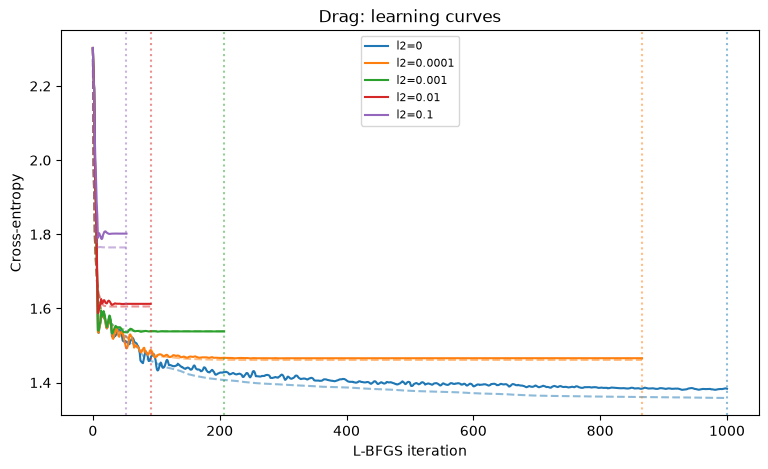

In [18]:
search_6 = run_stage(6, "Drag")

#### Interpretation


| Model | learning_rate | train_loss | val_loss | val_F1 | val_accuracy | landing_score | landing_success | tuning_time |
| ----- | ------------- | ---------- | -------- | ------ | ------------ | ------------- | --------------- | ----------- |
| Baseline | 3 | 0.7755 | 0.7800 | 0.200 | 0.768 | 47.1 | 0 | 10min 35s | 
| Class Weighting | 3 | 1.5938 | 1.5899 | 0.248 | 0.391 | 60.6 | 0 | 17min 8s |
| L-BFGS | --- | 1.5661 | 1.5862 | 0.251 | 0.389 | 72.9 | 7 | 52s |
| Constant Velocity | --- | 1.4322 | 1.4719 | 0.282 | 0.417 | 74.3 | 9 | 2min 19s |
| Gravity | --- | 1.3687 | 1.3915 | 0.316 | 0.486 | 77.2 | 9 | 1min 40s |
| Drag | --- | 1.3583 | 1.3833 | 0.309 | 0.465 | 78.8 | 9 | 1min 55s |

Other than adding the horizontal projections this is probably the most realistic model. However, the accuracy and F1 score reduce, but this does not correlate with the landing performance as that still increases. One important remark is that the landing performance is only one 10 runs so may not be as indicative as the F1 and accuracy over 100 runs.

#### Basis Functions 4 - Thrust

The current thrust and gimbal are held fixed over the projection horizon (Change 4).

l2=0: val macro F1 0.294, 1000 epochs (max_epochs)                                                 
l2=0.0001: val macro F1 0.274, 702 epochs (converged)                                              
l2=0.001: val macro F1 0.264, 423 epochs (converged)                                               
l2=0.01: val macro F1 0.251, 133 epochs (converged)                                                
l2=0.1: val macro F1 0.213, 76 epochs (converged)                                                  
Saved best model (l2=0, val macro F1=0.294) to 07_thrust_best.npz


,l2,best_epoch,epochs_run,stop_reason,train_loss,val_loss,val_accuracy,val_macro_f1,f1_class_0,f1_class_1,f1_class_2,f1_class_3,f1_class_4,f1_class_5,f1_class_6,f1_class_7,f1_class_8,f1_class_9
0,0,1000,1000,max_epochs,1.4619,1.4975,0.462,0.294,0.866,0.177,0.537,0.205,0.150,0.316,0.158,0.206,0.129,0.199
1,0.0001,702,702,converged,1.5228,1.5408,0.435,0.274,0.823,0.172,0.515,0.205,0.138,0.312,0.155,0.140,0.149,0.134
2,0.001,423,423,converged,1.5636,1.5722,0.412,0.264,0.820,0.161,0.482,0.205,0.139,0.297,0.151,0.114,0.168,0.099
3,0.01,133,133,converged,1.6318,1.6535,0.384,0.251,0.829,0.161,0.435,0.198,0.131,0.284,0.138,0.092,0.149,0.090
4,0.1,76,76,converged,1.8106,1.8768,0.303,0.213,0.831,0.142,0.299,0.166,0.096,0.262,0.101,0.056,0.117,0.062


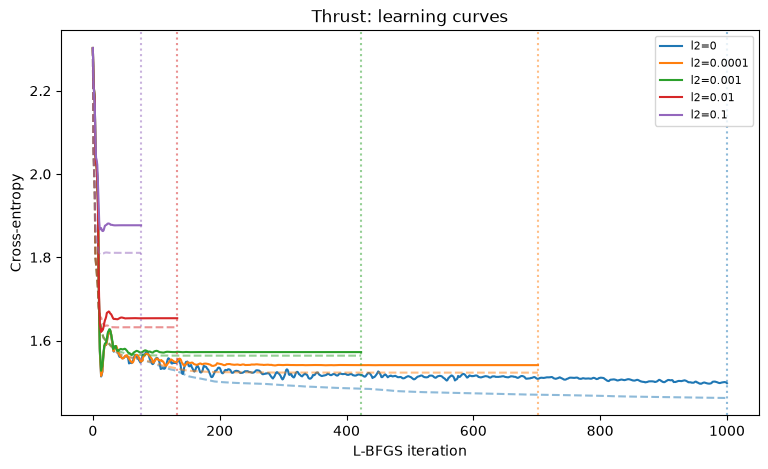

In [19]:
search_7 = run_stage(7, "Thrust")

#### Interpretation


| Model | learning_rate | train_loss | val_loss | val_F1 | val_accuracy | landing_score | landing_success | tuning_time |
| ----- | ------------- | ---------- | -------- | ------ | ------------ | ------------- | --------------- | ----------- |
| Baseline | 3 | 0.7755 | 0.7800 | 0.200 | 0.768 | 47.1 | 0 | 10min 35s | 
| Class Weighting | 3 | 1.5938 | 1.5899 | 0.248 | 0.391 | 60.6 | 0 | 17min 8s |
| L-BFGS | --- | 1.5661 | 1.5862 | 0.251 | 0.389 | 72.9 | 7 | 52s |
| Constant Velocity | --- | 1.4322 | 1.4719 | 0.282 | 0.417 | 74.3 | 9 | 2min 19s |
| Gravity | --- | 1.3687 | 1.3915 | 0.316 | 0.486 | 77.2 | 9 | 1min 40s |
| Drag | --- | 1.3583 | 1.3833 | 0.309 | 0.465 | 78.8 | 9 | 1min 55s |
| Thrust | --- | 1.4619 | 1.4975 | 0.294 | 0.462 | 54.3 | 0 | 2min 9s |

This is quite obviously worse, as expected. No reason to carry this forward

#### Basis Functions 5 - Horizontal projection

Back to the drag model (no thrust), but also projecting $x$ and $v_x$, giving 6 projected quantities per horizon and 30 features in total (Change 5).

l2=0: val macro F1 0.315, 1000 epochs (max_epochs)                                                 
l2=0.0001: val macro F1 0.282, 536 epochs (converged)                                              
l2=0.001: val macro F1 0.260, 200 epochs (converged)                                               
l2=0.01: val macro F1 0.254, 83 epochs (converged)                                                 
l2=0.1: val macro F1 0.232, 54 epochs (converged)                                                  
Saved best model (l2=0, val macro F1=0.315) to 08_horizontal_best.npz


,l2,best_epoch,epochs_run,stop_reason,train_loss,val_loss,val_accuracy,val_macro_f1,f1_class_0,f1_class_1,f1_class_2,f1_class_3,f1_class_4,f1_class_5,f1_class_6,f1_class_7,f1_class_8,f1_class_9
0,0,1000,1000,max_epochs,1.3492,1.3763,0.482,0.315,0.853,0.187,0.573,0.218,0.159,0.313,0.151,0.199,0.281,0.213
1,0.0001,536,536,converged,1.4591,1.4651,0.445,0.282,0.833,0.174,0.529,0.211,0.157,0.288,0.150,0.153,0.179,0.141
2,0.001,200,200,converged,1.5379,1.5370,0.412,0.260,0.808,0.158,0.491,0.194,0.144,0.276,0.151,0.112,0.165,0.097
3,0.01,83,83,converged,1.5970,1.6056,0.403,0.254,0.815,0.161,0.482,0.201,0.137,0.268,0.141,0.095,0.155,0.085
4,0.1,54,54,converged,1.7500,1.7958,0.377,0.232,0.822,0.152,0.457,0.192,0.089,0.240,0.112,0.071,0.124,0.066


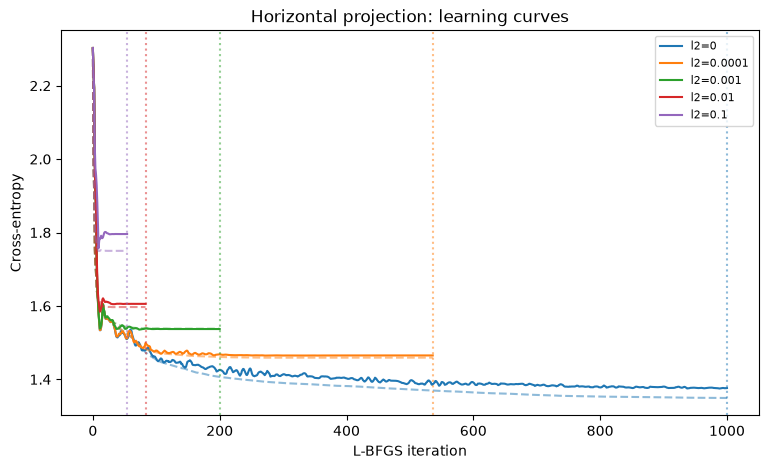

In [20]:
search_8 = run_stage(8, "Horizontal projection")

#### Interpretation


| Model | learning_rate | train_loss | val_loss | val_F1 | val_accuracy | landing_score | landing_success | tuning_time |
| ----- | ------------- | ---------- | -------- | ------ | ------------ | ------------- | --------------- | ----------- |
| Baseline | 3 | 0.7755 | 0.7800 | 0.200 | 0.768 | 47.1 | 0 | 10min 35s | 
| Class Weighting | 3 | 1.5938 | 1.5899 | 0.248 | 0.391 | 60.6 | 0 | 17min 8s |
| L-BFGS | --- | 1.5661 | 1.5862 | 0.251 | 0.389 | 72.9 | 7 | 52s |
| Constant Velocity | --- | 1.4322 | 1.4719 | 0.282 | 0.417 | 74.3 | 9 | 2min 19s |
| Gravity | --- | 1.3687 | 1.3915 | 0.316 | 0.486 | 77.2 | 9 | 1min 40s |
| Drag | --- | 1.3583 | 1.3833 | 0.309 | 0.465 | 78.8 | 9 | 1min 55s |
| Thrust | --- | 1.4619 | 1.4975 | 0.294 | 0.462 | 54.4 | 0 | 2min 9s |
| Drag + Horizontal | --- | 1.3492 | 1.3763 | 0.315 | 0.482 | 73.8 | 7 | 1min 35s

Based on the losses this is the best so far, however the F1 and accuracy are less than the Gravity example. Perhaps there is more to be gained with more iterations. This reduction in loss also does not transfer to the landing performance interestingly. Likely to do with the optimisation task. Optimising for agreement with the expert does not necessarily make a good controller.

# General Comments

Regularisation was worse in every case because the number of features used (max 30) was so much less than the number of samples (over 100k). Which meant that the model was extremely unlikely to overfit.

In general, there are definitely some optimisations to be made:
- Instead of limiting to 3s, it would be reasonable to add up to x seconds where x is the number of seconds until the rocket hit the ground
- Adding counterfactual basis functions. E.g. If i choose to turn on the engine to maximum thrust for this iteration does this move my projection closer or further away than the desired landing state. And add one per action.

If my aim was instead to optimise for F1 and accuracy I would've changed my basis functions and also my way of approaching the problem. Firstly, it would have been data oriented - I would have created plots, made observations and acted on them instead of trying to make basis functions that modeled the environment.

I hope this notebook gives you a reasonable introduction into another way that you can approach a machine learning problem. It's different to the data motivated one that we had before. As always, the aim is to have the simplest and most understandable model that performs well on the task.